# 02 v2: Desempenho em dados limpos no M4 Monthly (protocolo único v2)

**Fase 2a** da correção do projeto. Substitui, para fins de resultado, a Tabela 3 construída a partir dos notebooks 01 a 07 (os originais foram mantidos).

### O que mudou em relação aos notebooks 01 a 07
| Item | Antes | v2 |
|---|---|---|
| Amostra | duas amostras de 200 séries (NB01 a 04b e NB05 a 07, só 3 em comum) | uma amostra única (NB05 a 09, ordem do arquivo, SEED=42) |
| Features de ML | lag_1..12, roll_mean e roll_std (12), lag_season (= lag_12), lag_season2 | lag_1..12, roll_mean_3, roll_std_3, roll_mean_6 (15, sem duplicata) |
| SARIMA automático | ordem escolhida com a série inteira (vazamento) | ordem escolhida em cada janela, só com o treino |
| SARIMA (ambos) | ajustes com verossimilhança degenerada aceitos como válidos | rejeitados; heurístico cai no sazonal ingênuo (registrado) |
| Status | erros e fallbacks misturados | OK, FALLBACK_SNAIVE, FALLBACK_MEAN, ERRO, SEM_JANELA |
| R² | forçado pelo sklearn em teste constante | indefinido (NaN) |

Inalterado: janelas por `linspace(24, n - 18, 3)`, H=18, MAPE com máscara, mediana por janela e depois entre séries, hiperparâmetros (RF 100 árvores e min_samples_leaf=2; GB 100, lr 0,1, profundidade 3, subsample 0,8; SVR C=1, ε=0,1, rbf).

Os resultados vêm de `scripts/run_v2.py` (execução paralela com checkpoint) e estão em `results/v2/m4/limpo/`. Este notebook só lê os caches.

In [1]:
import sys, json, warnings
warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_root = Path.cwd().resolve()
PROJECT_ROOT = next(c for c in (_root, *_root.parents) if (c / 'src' / 'pipeline_v2.py').is_file())
sys.path.insert(0, str(PROJECT_ROOT))
from src import pipeline_v2 as pv

DIR_LIMPO = PROJECT_ROOT / 'results' / 'v2' / 'm4' / 'limpo'
RES_ANT   = PROJECT_ROOT / 'results'
H = 18

NOMES = {'holt_winters': 'Holt-Winters', 'persistence': 'Persistência', 'ses': 'SES',
         'sarima_auto': 'SARIMA automático', 'gbt': 'Gradient Boosting', 'sarima_heuristic': 'SARIMA heurístico',
         'random_forest': 'Random Forest', 'seasonal_naive': 'Sazonal ingênuo', 'svr': 'SVR',
         'mean': 'Média histórica'}

arquivos = sorted(DIR_LIMPO.glob('m4_limpo_*_by_window.csv'))
df = pd.concat([pd.read_csv(f) for f in arquivos], ignore_index=True)
print(f'{len(arquivos)} caches | {len(df):,} janelas | {df.unique_id.nunique()} séries | modelos: {sorted(df.model.unique())}')
faltando = sorted(set(pv.MODELOS) - set(df.model.unique()))
if faltando:
    print(f'ATENÇÃO: ainda sem cache (rodando em segundo plano?): {faltando}')
meta = json.loads((arquivos[0].with_name(arquivos[0].name + '.meta.json')).read_text(encoding='utf-8'))
print('pipeline_sha256 =', meta['pipeline_sha256'][:16], '| dados:', [(d['arquivo'], d['sha256'][:12]) for d in meta['dados']])

10 caches | 6,000 janelas | 200 séries | modelos: ['gbt', 'holt_winters', 'mean', 'persistence', 'random_forest', 'sarima_auto', 'sarima_heuristic', 'seasonal_naive', 'ses', 'svr']
pipeline_sha256 = 4cbb246963a18f57 | dados: [('Monthly-train.csv', '63aaa56198b4')]


## 1. Taxas de status por modelo e fallback por janela
`SEM_JANELA` não ocorre no M4 (todas as séries têm n >= 42). Fallbacks esperados: SARIMA heurístico na 1ª janela (24 obs, verossimilhança degenerada) e SVR quando o alvo do treino é constante.

In [2]:
taxas = (100 * pv.taxas_status(df)).round(1)
taxas.index = [NOMES[m] for m in taxas.index]
print('Taxas de status (% das janelas):')
print(taxas.to_string())

fb_janela = (100 * pv.taxas_fallback_por_janela(df)).round(1)
fb_janela.index = [NOMES[m] for m in fb_janela.index]
fb_janela.columns = [f'janela {int(c)}' for c in fb_janela.columns]
print('\nFallback por janela (% das séries):')
print(fb_janela.to_string())

taxas.to_csv(DIR_LIMPO / 'm4_limpo_taxas_status.csv')
fb_janela.to_csv(DIR_LIMPO / 'm4_limpo_fallback_por_janela.csv')

Taxas de status (% das janelas):
status                OK  FALLBACK_SNAIVE  FALLBACK_MEAN  ERRO  SEM_JANELA
Gradient Boosting  100.0              0.0            0.0   0.0         0.0
Holt-Winters       100.0              0.0            0.0   0.0         0.0
Média histórica    100.0              0.0            0.0   0.0         0.0
Persistência       100.0              0.0            0.0   0.0         0.0
Random Forest      100.0              0.0            0.0   0.0         0.0
SARIMA automático  100.0              0.0            0.0   0.0         0.0
SARIMA heurístico   66.7             33.3            0.0   0.0         0.0
Sazonal ingênuo    100.0              0.0            0.0   0.0         0.0
SES                100.0              0.0            0.0   0.0         0.0
SVR                 99.5              0.0            0.5   0.0         0.0

Fallback por janela (% das séries):
                   janela 1  janela 2  janela 3
Gradient Boosting       0.0       0.0       0.0
Holt-Wint

## 2. Tabela 3 v2: MAPE, MAE e R² medianos, com e sem as janelas de fallback
"Sem fallback" exclui as janelas em fallback antes da mediana por série; séries sem nenhuma janela válida saem daquele modelo (coluna `n_series`).

In [3]:
def tabela3(incluir_fallback):
    r = pv.resumo_modelos(pv.agregar_por_serie(df, incluir_fallback))
    r['rank'] = r['mape'].rank(method='min').astype(int)
    return r

t_com, t_sem = tabela3(True), tabela3(False)
tab3 = pd.DataFrame({
    'Família'            : t_com['familia'],
    'MAPE (%)'           : t_com['mape'].round(2),
    'MAE'                : t_com['mae'].round(2),
    'R² mediano'         : t_com['r2'].round(2),
    'Rank'               : t_com['rank'],
    'MAPE sem fallback'  : t_sem['mape'].round(2),
    'Rank sem fallback'  : t_sem['rank'],
    'Séries sem fallback': t_sem['n_series'],
    'Fallback (% jan.)'  : (100 * pv.taxas_status(df)[[pv.FB_SNAIVE, pv.FB_MEAN]].sum(axis=1)).round(1),
}).sort_values('Rank')
tab3.index = [NOMES[m] for m in tab3.index]
print('Tabela 3 v2: M4 Monthly, 200 séries (amostra única), H=18, N_ORIGINS=3')
print(tab3.to_string())
tab3.to_csv(DIR_LIMPO / 'tabela3_v2_m4.csv')

fam = t_com.groupby('familia')['mape'].agg(['min', 'median']).sort_values('min').round(2)
fam.columns = ['MAPE do melhor modelo', 'MAPE mediano da família']
print('\nRanking por família (melhor modelo de cada família):')
print(fam.to_string())
fam.to_csv(DIR_LIMPO / 'ranking_familias_v2_m4.csv')

Tabela 3 v2: M4 Monthly, 200 séries (amostra única), H=18, N_ORIGINS=3
                                  Família  MAPE (%)     MAE  R² mediano  Rank  MAPE sem fallback  Rank sem fallback  Séries sem fallback  Fallback (% jan.)
Holt-Winters       Suavização exponencial      8.36  325.29       -1.22     1               8.36                  1                  200                0.0
SARIMA automático                   ARIMA      8.91  344.72       -1.33     2               8.91                  2                  200                0.0
Gradient Boosting                      ML      9.06  290.35       -1.09     3               9.06                  3                  200                0.0
SES                Suavização exponencial      9.68  328.89       -1.06     4               9.68                  4                  200                0.0
SARIMA heurístico                   ARIMA      9.72  354.00       -1.74     5              10.69                  7                  200             

## 3. Comparação com a Tabela 3 antiga
Valores antigos: os publicados na Tabela 3 da dissertação (e, quando há, a mediana recalculada dos CSVs antigos). Lembre que na tabela antiga os modelos estatísticos e os de ML vinham de amostras diferentes.

In [4]:
TAB3_ANTIGA = {   # dissertação, Tabela 3 (MAPE %, rank)
    'holt_winters': (8.26, 1), 'persistence': (8.70, 2), 'ses': (8.78, 3), 'sarima_auto': (9.12, 4),
    'gbt': (9.90, 5), 'sarima_heuristic': (10.10, 6), 'random_forest': (10.59, 7),
    'seasonal_naive': (11.06, 8), 'svr': (11.13, 9), 'mean': (18.60, 10),
}
AMOSTRA_ANTIGA = {m: ('NB05 a 07 (= v2)' if m in ('gbt', 'random_forest', 'svr') else 'NB01 a 04b (alfabética)')
                  for m in TAB3_ANTIGA}
comp = pd.DataFrame({
    'MAPE antigo'  : {m: v[0] for m, v in TAB3_ANTIGA.items()},
    'Rank antigo'  : {m: v[1] for m, v in TAB3_ANTIGA.items()},
    'Amostra antiga': AMOSTRA_ANTIGA,
})
comp['MAPE v2'] = t_com['mape'].round(2)
comp['Rank v2'] = t_com['rank']
comp['Δ MAPE (p.p.)'] = (comp['MAPE v2'] - comp['MAPE antigo']).round(2)
comp['Δ rank'] = comp['Rank v2'] - comp['Rank antigo']
comp['Mudou de posição'] = np.where(comp['Δ rank'].fillna(0) != 0, 'SIM', '')
comp = comp.sort_values('Rank v2')
comp.index = [NOMES[m] for m in comp.index]
print(comp.to_string())
comp.to_csv(DIR_LIMPO / 'comparacao_tabela3_antiga_v2_m4.csv')

                   MAPE antigo  Rank antigo           Amostra antiga  MAPE v2  Rank v2  Δ MAPE (p.p.)  Δ rank Mudou de posição
Holt-Winters              8.26            1  NB01 a 04b (alfabética)     8.36        1           0.10       0                 
SARIMA automático         9.12            4  NB01 a 04b (alfabética)     8.91        2          -0.21      -2              SIM
Gradient Boosting         9.90            5         NB05 a 07 (= v2)     9.06        3          -0.84      -2              SIM
SES                       8.78            3  NB01 a 04b (alfabética)     9.68        4           0.90       1              SIM
SARIMA heurístico        10.10            6  NB01 a 04b (alfabética)     9.72        5          -0.38      -1              SIM
Persistência              8.70            2  NB01 a 04b (alfabética)     9.75        6           1.05       4              SIM
Random Forest            10.59            7         NB05 a 07 (= v2)    10.13        7          -0.46       0  

## 4. Sanidade: onde o protocolo NÃO mudou, o v2 reproduz os caches antigos?
Persistência, média, sazonal ingênuo, SES e Holt-Winters usam as mesmas funções e janelas dos NB01 a 03. Rodando o v2 na **amostra antiga** (NB01 a 04b, ordem alfabética), o MAPE por janela deve ser idêntico. Para o SARIMA heurístico, só as janelas 2 e 3 (a 1ª agora é fallback por verossimilhança degenerada).

In [5]:
def gerar_sanidade():
    tr = pd.read_csv(PROJECT_ROOT / 'data' / 'raw' / 'Monthly-train.csv')
    idc = tr.columns[0]
    ids_ant = np.random.default_rng(pv.SEED).choice(np.sort(tr[idc].unique()), size=200, replace=False)
    ser = {u: tr.loc[tr[idc] == u].iloc[0, 1:].dropna().values.astype(float) for u in ids_ant}
    mods = ['persistence', 'mean', 'seasonal_naive', 'ses', 'holt_winters', 'sarima_heuristic']
    v2 = pv.avaliar_base([ser[u] for u in ids_ant], list(ids_ant), mods, H, n_jobs=6)
    antigos = pd.concat([
        pd.read_csv(RES_ANT / 'results_nb02_by_window.csv'),
        pd.read_csv(RES_ANT / 'results_ses_by_window.csv').assign(model='ses'),
        pd.read_csv(RES_ANT / 'results_sarima_heuristic_by_window.csv').assign(model='sarima_heuristic'),
    ])[['unique_id', 'model', 'origin', 'mape']]
    m = v2.merge(antigos, on=['unique_id', 'model', 'origin'], suffixes=('_v2', '_antigo'))
    return m[['unique_id', 'model', 'janela', 'origin', 'status', 'mape_v2', 'mape_antigo']]

san = pv.cache_csv(DIR_LIMPO / 'sanidade_amostra_antiga_m4.csv', gerar_sanidade,
                   {'descricao': 'v2 na amostra antiga (NB01 a 04b) x caches antigos'},
                   arquivos_dados=[PROJECT_ROOT / 'data' / 'raw' / 'Monthly-train.csv'])
san['dif'] = (san['mape_v2'] - san['mape_antigo']).abs()
res = san[san['status'] == pv.OK].groupby('model').agg(janelas=('dif', 'size'), dif_max=('dif', 'max'),
                                                        iguais=('dif', lambda x: (x < 1e-6).mean() * 100))
res.index = [NOMES[m] for m in res.index]
res['dif_max'] = res['dif_max'].map(lambda v: f'{v:.2e}')
res['iguais'] = res['iguais'].round(1).astype(str) + '%'
print('MAPE por janela, v2 x cache antigo (janelas com status OK):')
print(res.to_string())

MAPE por janela, v2 x cache antigo (janelas com status OK):
                   janelas   dif_max  iguais
Holt-Winters           600  2.84e-14  100.0%
Média histórica        600  3.55e-15  100.0%
Persistência           600  3.55e-15  100.0%
SARIMA heurístico      399  3.55e-15  100.0%
Sazonal ingênuo        600  3.55e-15  100.0%
SES                    600  2.84e-14  100.0%


### 4.1 Modelos de ML: o protocolo mudou (features), então não há reprodução exata esperada
A amostra dos NB05 a 07 é a mesma do v2; a diferença vem das features (sem lag_season duplicado, médias móveis de 3 e 6) e, no RF, do código atual (o cache antigo não era reproduzível, item C9). Mostramos a diferença pareada por série.

In [6]:
bs_v2 = pv.agregar_por_serie(df)
linhas = []
for m, arq in [('random_forest', 'results_rf_by_series.csv'), ('gbt', 'results_gbt_by_series.csv'),
               ('svr', 'results_svr_by_series.csv')]:
    ant = pd.read_csv(RES_ANT / arq)[['unique_id', 'mape']]
    j = bs_v2[bs_v2.model == m][['unique_id', 'mape']].merge(ant, on='unique_id', suffixes=('_v2', '_antigo'))
    d = j['mape_v2'] - j['mape_antigo']
    linhas.append({'modelo': NOMES[m], 'séries pareadas': len(j), 'MAPE antigo': j['mape_antigo'].median(),
                   'MAPE v2': j['mape_v2'].median(), 'mediana Δ pareada (p.p.)': d.median(),
                   'v2 melhor em (% séries)': 100 * (d < 0).mean()})
print(pd.DataFrame(linhas).round(2).to_string(index=False))

           modelo  séries pareadas  MAPE antigo  MAPE v2  mediana Δ pareada (p.p.)  v2 melhor em (% séries)
    Random Forest              200        10.59    10.13                     -0.01                     51.5
Gradient Boosting              200         9.90     9.06                     -0.11                     57.0
              SVR              200        11.13    11.52                     -0.00                     50.5


## 5. SARIMA: resultados com e sem fallback, por janela

In [7]:
sar = df[df.model.isin(['sarima_heuristic', 'sarima_auto'])].copy()
if len(sar):
    g = sar.groupby(['model', 'janela'])
    t = pd.DataFrame({
        'fallback (%)'       : 100 * g['status'].apply(lambda s: s.isin([pv.FB_SNAIVE, pv.FB_MEAN]).mean()),
        'MAPE mediano (com)' : g['mape'].median(),
        'MAPE mediano (sem)' : sar[sar.status == pv.OK].groupby(['model', 'janela'])['mape'].median(),
    }).round(2)
    print(t.to_string())
    if 'sarima_auto' in sar.model.unique():
        info = sar[(sar.model == 'sarima_auto') & (sar['info'].fillna('') != '')]['info'].map(json.loads)
        print(f"\nSARIMA auto: busca incompleta (tempo) em {sum(not i.get('busca_completa', True) for i in info)} janelas; "
              f"previsões explosivas sinalizadas: {sum(bool(i.get('explosiva')) for i in info)}")
        print('Candidatos degenerados por janela (mediana):',
              sar[sar.model == 'sarima_auto'].assign(n=info.map(lambda i: i.get('n_degenerados'))).groupby('janela')['n'].median().to_dict())

                         fallback (%)  MAPE mediano (com)  MAPE mediano (sem)
model            janela                                                      
sarima_auto      1                0.0               12.21               12.21
                 2                0.0                9.09                9.09
                 3                0.0                7.99                7.99
sarima_heuristic 1              100.0               13.21                 NaN
                 2                0.0                9.58                9.58
                 3                0.0                9.15                9.15

SARIMA auto: busca incompleta (tempo) em 0 janelas; previsões explosivas sinalizadas: 14
Candidatos degenerados por janela (mediana): {1: 54.0, 2: 0.0, 3: 0.0}


## 6. Figura: distribuição do MAPE por modelo (equivalente à Fig. 9)

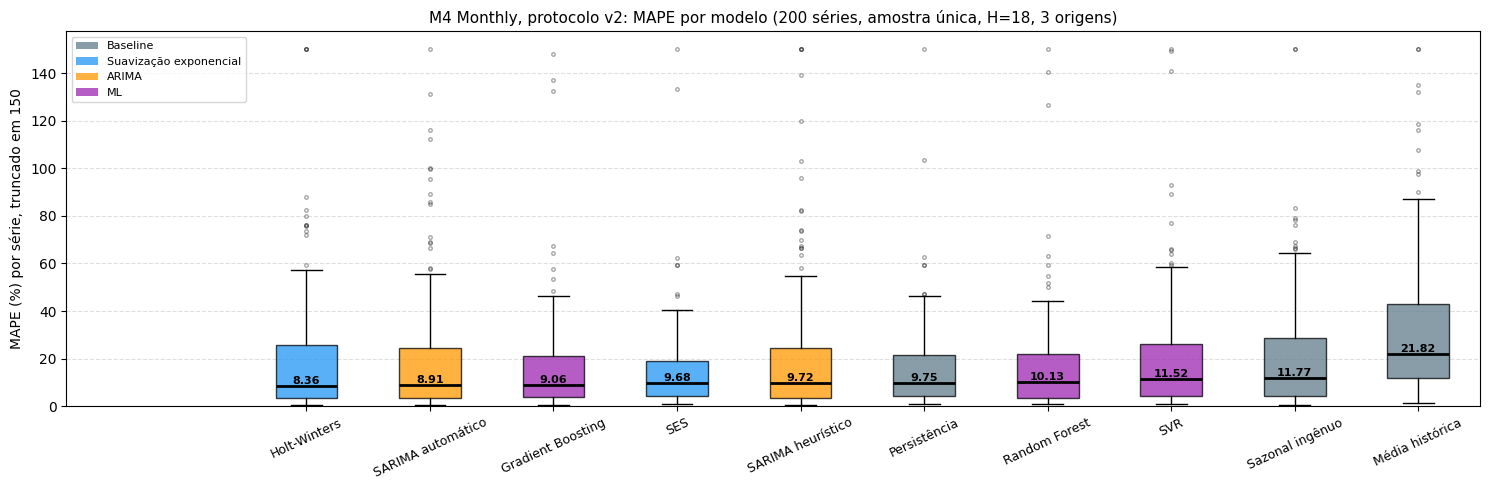

In [8]:
bs = pv.agregar_por_serie(df)
ordem = [m for m in t_com.index]
cores = {'Baseline': '#607D8B', 'Suavização exponencial': '#2196F3', 'ARIMA': '#FF9800', 'ML': '#9C27B0'}
dados = [bs[bs.model == m]['mape'].dropna() for m in ordem]
fig, ax = plt.subplots(figsize=(15, 5))
bp = ax.boxplot([d.clip(upper=150) for d in dados], patch_artist=True,
                medianprops=dict(color='black', linewidth=2), flierprops=dict(marker='o', markersize=2.5, alpha=0.35))
for patch, m in zip(bp['boxes'], ordem):
    patch.set_facecolor(cores[pv.FAMILIA[m]]); patch.set_alpha(0.75)
for i, d in enumerate(dados):
    ax.text(i + 1, d.median(), f'{d.median():.2f}', ha='center', va='bottom', fontsize=8, fontweight='bold')
ax.set_xticks(range(1, len(ordem) + 1)); ax.set_xticklabels([NOMES[m] for m in ordem], rotation=25, fontsize=9)
ax.set_ylabel('MAPE (%) por série, truncado em 150'); ax.grid(axis='y', linestyle='--', alpha=0.4)
for fam_, c in cores.items():
    ax.bar(0, 0, color=c, alpha=0.75, label=fam_)
ax.legend(fontsize=8, loc='upper left')
ax.set_title('M4 Monthly, protocolo v2: MAPE por modelo (200 séries, amostra única, H=18, 3 origens)', fontsize=11)
plt.tight_layout()
plt.savefig(DIR_LIMPO / 'fig_v2_m4_boxplot_mape.png', dpi=150, bbox_inches='tight')
plt.show()